# Final Tier-2 Fusion Weight + Threshold Selection Experiment

Selects the final Tier-2 weighted-fusion configuration **using validation data only** from five **predefined** weighting strategies, then freezes the selected weights + threshold and evaluates the held-out test set **once**.

**Selection criterion (fixed before any test look):**
> Maximize validation **Recall** subject to validation **FPR ≤ 1%**.

**Tier-1 inputs (canonical, finalized, reproducible):**

| Modality | Model | Ratio |
|---|---|---|
| HTTP | MLP | 6:1 |
| File/Device | MLP | 4:1 |
| Email | MLP | 4:1 |
| Logon | MLP | 4:1 |

The Tier-1 pipeline is **not** modified here; this experiment only selects the fusion weights + threshold. It is **not** a Fusion redesign and trains no meta-model.

## 1. Setup + Load Canonical Tier-1 Scores

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import (recall_score, precision_score, f1_score, accuracy_score,
                             roc_auc_score, confusion_matrix, roc_curve)
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings('ignore')

# Project root (portability convention)
_curr = Path.cwd()
while not (_curr / 'pyproject.toml').exists() and _curr != _curr.parent:
    _curr = _curr.parent
PROJECT_ROOT = _curr
TIER1_SCORES = PROJECT_ROOT / 'tier1' / 'scores'
WEEK3_DIR = PROJECT_ROOT / 'week3'

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# ---- Load canonical Tier-1 scores ----
df_val = pd.read_csv(TIER1_SCORES / 'tier1_validation_scores.csv')
df_test = pd.read_csv(TIER1_SCORES / 'tier1_test_scores.csv')

# ---- Input schema validation (fail loudly) ----
required = {'user', 'week', 'day', 'label'}
scores = ['logon_score', 'email_score', 'file_device_score', 'http_score']
for name, d in [('Validation', df_val), ('Test', df_test)]:
    missing = required - set(d.columns)
    assert not missing, f'{name}: missing {missing}'
    for sc in scores:
        assert sc in d.columns, f'{name}: missing {sc}'
    dup = int(d.duplicated(subset=['user', 'week', 'day']).sum())
    assert dup == 0, f'{name}: {dup} duplicate (user, week, day)'

# ---- Provenance ----
print('Tier-1 validation score file:', TIER1_SCORES / 'tier1_validation_scores.csv')
print('Tier-1 test score file:      ', TIER1_SCORES / 'tier1_test_scores.csv')
print('Validation rows:', len(df_val), '| users:', df_val['user'].nunique(), '| positives:', int(df_val['label'].sum()))
print('Test rows:      ', len(df_test), '| users:', df_test['user'].nunique(), '| positives:', int(df_test['label'].sum()))
print('User separation (val ∩ test):', len(set(df_val['user'].unique()) & set(df_test['user'].unique())))
print('Provenance: finalized Tier-1 MLPs -> HTTP 6:1, File/Device 4:1, Email 4:1, Logon 4:1.')

# Label consistency check
assert df_val['label'].isin([0, 1]).all() and df_test['label'].isin([0, 1]).all()
print('Labels are binary 0/1 in both splits.')

df_val.head()

Tier-1 validation score file: C:\insider_threat_detection_project2\tier1\scores\tier1_validation_scores.csv
Tier-1 test score file:       C:\insider_threat_detection_project2\tier1\scores\tier1_test_scores.csv
Validation rows: 61076 | users: 200 | positives: 191
Test rows:       61203 | users: 200 | positives: 201
User separation (val ∩ test): 0
Provenance: finalized Tier-1 MLPs -> HTTP 6:1, File/Device 4:1, Email 4:1, Logon 4:1.
Labels are binary 0/1 in both splits.


,user,week,day,label,logon_score,email_score,file_device_score,http_score
0,1.0,5.0,37.0,0,0.109435,0.252510,0.004813,0.002560
1,1.0,5.0,38.0,0,0.109435,0.260830,0.004813,0.002291
2,1.0,5.0,39.0,0,0.109435,0.219151,0.004813,0.001726
3,1.0,6.0,42.0,0,0.726668,0.036856,0.009190,0.000577
4,1.0,6.0,43.0,0,0.109084,0.050731,0.009190,0.001387


## 2. Predefined Weighting Strategies (fixed in advance, no post-hoc additions)

In [2]:
# The five candidate strategies are FIXED before model selection.
strategies = {
    'Domain':               {'http': 0.40, 'file_device': 0.40, 'logon': 0.10, 'email': 0.10},
    'Equal':                {'http': 0.25, 'file_device': 0.25, 'logon': 0.25, 'email': 0.25},
    'HTTP-dominant':        {'http': 0.60, 'file_device': 0.20, 'logon': 0.10, 'email': 0.10},
    'File-dominant':        {'http': 0.20, 'file_device': 0.60, 'logon': 0.10, 'email': 0.10},
    'Recall-proportional':  None,  # computed below from VALIDATION modality recalls only
}

def fused(d, w):
    return (d['http_score'] * w['http'] +
            d['file_device_score'] * w['file_device'] +
            d['logon_score'] * w['logon'] +
            d['email_score'] * w['email'])

# ---- Recall-proportional weights: validation-set modality recall only ----
rec = {
    'http': recall_score(df_val['label'], (df_val['http_score'] > 0.5).astype(int), zero_division=0),
    'file_device': recall_score(df_val['label'], (df_val['file_device_score'] > 0.5).astype(int), zero_division=0),
    'logon': recall_score(df_val['label'], (df_val['logon_score'] > 0.5).astype(int), zero_division=0),
    'email': recall_score(df_val['label'], (df_val['email_score'] > 0.5).astype(int), zero_division=0),
}
print('Validation modality recalls (threshold 0.5):')
for k, v in rec.items():
    print(f'  {k:12s}: {v:.4f}')
tot = sum(rec.values())
strategies['Recall-proportional'] = {k: v / tot for k, v in rec.items()}
print('\nRecall-proportional weights (normalized to sum 1.0):')
for k, v in strategies['Recall-proportional'].items():
    print(f'  {k:12s}: {v:.4f}')
print('Sum:', round(sum(strategies['Recall-proportional'].values()), 6))

for name, w in strategies.items():
    assert abs(sum(w.values()) - 1.0) < 1e-9, f'{name}: weights must sum to 1'
    print(f'Strategy {name:20s} weights: ' + ', '.join(f'{k}={v:.2f}' for k, v in w.items()))

Validation modality recalls (threshold 0.5):
  http        : 0.9372
  file_device : 0.5236
  logon       : 0.0733
  email       : 0.2670

Recall-proportional weights (normalized to sum 1.0):
  http        : 0.5203
  file_device : 0.2907
  logon       : 0.0407
  email       : 0.1483
Sum: 1.0
Strategy Domain               weights: http=0.40, file_device=0.40, logon=0.10, email=0.10
Strategy Equal                weights: http=0.25, file_device=0.25, logon=0.25, email=0.25
Strategy HTTP-dominant        weights: http=0.60, file_device=0.20, logon=0.10, email=0.10
Strategy File-dominant        weights: http=0.20, file_device=0.60, logon=0.10, email=0.10
Strategy Recall-proportional  weights: http=0.52, file_device=0.29, logon=0.04, email=0.15


## 3. Validation-Only Model Selection (criterion: max Recall s.t. FPR ≤ 1%)

In [3]:
# For each strategy: sweep thresholds on VALIDATION only; pick max Recall with FPR <= 1%.
thresholds = np.arange(0.05, 0.96, 0.01)
FPR_CAP = 0.01  # 1% operating constraint (selection criterion)

rows = []
for name, w in strategies.items():
    s_val = fused(df_val, w)
    best = None
    for t in thresholds:
        preds = (s_val > t).astype(int)
        rec = recall_score(df_val['label'], preds, zero_division=0)
        tn, fp, fn, tp = confusion_matrix(df_val['label'], preds).ravel()
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
        prec = precision_score(df_val['label'], preds, zero_division=0)
        f1 = f1_score(df_val['label'], preds, zero_division=0)
        acc = accuracy_score(df_val['label'], preds)
        feasible = fpr <= FPR_CAP
        key = (feasible, rec, -fpr if feasible else -fpr, t)  # feasible first, then max rec, then min fpr
        if best is None or key > best[0]:
            best = (key, t, rec, fpr, prec, f1, acc)
    _, t, rec, fpr, prec, f1, acc = best
    auc = roc_auc_score(df_val['label'], s_val)
    rows.append({'Strategy': name, 'HTTP W': w['http'], 'File W': w['file_device'],
                 'Logon W': w['logon'], 'Email W': w['email'],
                 'Best Threshold': t, 'Validation Recall': rec, 'Validation FPR': fpr,
                 'Validation Precision': prec, 'Validation F1': f1,
                 'Validation Accuracy': acc, 'Validation AUC': auc,
                 'Feasible (FPR<=1%)': bool(fpr <= FPR_CAP)})

comp = pd.DataFrame(rows)
comp = comp[['Strategy', 'HTTP W', 'File W', 'Logon W', 'Email W', 'Best Threshold',
             'Validation Recall', 'Validation FPR', 'Validation Precision',
             'Validation F1', 'Validation Accuracy', 'Validation AUC', 'Feasible (FPR<=1%)']]
comp['Best Threshold'] = comp['Best Threshold'].astype(float)
display(Markdown('### Validation comparison table (criterion: max Recall s.t. FPR ≤ 1%)'))
display(comp.round(4))

# ---- Select the strategy ----
feasible = comp[comp['Feasible (FPR<=1%)']]
if len(feasible) == 0:
    print('\n[WARNING] No strategy satisfies FPR <= 1% on validation.')
    selected = comp.loc[comp['Validation FPR'].idxmin()]
    print('Using strategy with minimum validation FPR (constraint infeasible).')
else:
    selected = feasible.loc[feasible['Validation Recall'].idxmax()]
    print('\n[SELECTED] Strategy maximizing validation Recall subject to FPR <= 1%:')

selected_strategy = selected['Strategy']
selected_weights = dict(strategies[selected_strategy])
selected_threshold = float(selected['Best Threshold'])

print(f'  Weight strategy: {selected_strategy}')
print(f'  Weights: HTTP={selected_weights["http"]:.2f} File={selected_weights["file_device"]:.2f} '
      f'Logon={selected_weights["logon"]:.2f} Email={selected_weights["email"]:.2f}')
print(f'  Decision threshold: {selected_threshold:.2f}')
print(f'  Validation Recall: {selected["Validation Recall"]:.4f}')
print(f'  Validation FPR:    {selected["Validation FPR"]:.4f}')
print(f'  Validation AUC:    {selected["Validation AUC"]:.4f}')

### Validation comparison table (criterion: max Recall s.t. FPR ≤ 1%)

,Strategy,HTTP W,File W,Logon W,Email W,Best Threshold,Validation Recall,Validation FPR,Validation Precision,Validation F1,Validation Accuracy,Validation AUC,Feasible (FPR<=1%)
0,Domain,0.4000,0.4000,0.1000,0.1000,0.41,0.9476,0.0075,0.2846,0.4377,0.9924,0.9948,True
1,Equal,0.2500,0.2500,0.2500,0.2500,0.33,0.9319,0.0087,0.2518,0.3964,0.9911,0.9932,True
2,HTTP-dominant,0.6000,0.2000,0.1000,0.1000,0.26,0.9791,0.0080,0.2783,0.4334,0.9920,0.9960,True
3,File-dominant,0.2000,0.6000,0.1000,0.1000,0.56,0.4817,0.0095,0.1373,0.2137,0.9889,0.9670,True
4,Recall-proportional,0.5203,0.2907,0.0407,0.1483,0.31,0.9738,0.0095,0.2438,0.3899,0.9905,0.9961,True



[SELECTED] Strategy maximizing validation Recall subject to FPR <= 1%:
  Weight strategy: HTTP-dominant
  Weights: HTTP=0.60 File=0.20 Logon=0.10 Email=0.10
  Decision threshold: 0.26
  Validation Recall: 0.9791
  Validation FPR:    0.0080
  Validation AUC:    0.9960


## 4. FREEZE the selected configuration

In [4]:
# FROZEN — do not modify based on any test result.
FROZEN_STRATEGY = selected_strategy
FROZEN_WEIGHTS = dict(selected_weights)
FROZEN_THRESHOLD = selected_threshold

print('FINAL FROZEN TIER-2 CONFIGURATION')
print('=' * 50)
print('Weight strategy :', FROZEN_STRATEGY)
print('HTTP            :', FROZEN_WEIGHTS['http'])
print('File/Device     :', FROZEN_WEIGHTS['file_device'])
print('Logon           :', FROZEN_WEIGHTS['logon'])
print('Email           :', FROZEN_WEIGHTS['email'])
print('Decision threshold:', FROZEN_THRESHOLD)
print('Validation Recall:', float(selected['Validation Recall']))
print('Validation FPR   :', float(selected['Validation FPR']))
print('Validation AUC   :', float(selected['Validation AUC']))
print('=' * 50)

FINAL FROZEN TIER-2 CONFIGURATION
Weight strategy : HTTP-dominant
HTTP            : 0.6
File/Device     : 0.2
Logon           : 0.1
Email           : 0.1
Decision threshold: 0.26000000000000006
Validation Recall: 0.9790575916230366
Validation FPR   : 0.007965837234129917
Validation AUC   : 0.9960418039845955


## 5. Evaluate the frozen configuration on the held-out Test set (ONCE)

In [5]:
# Test set is touched ONLY here, with the frozen weights + threshold.
s_test = fused(df_test, FROZEN_WEIGHTS)
preds_test = (s_test > FROZEN_THRESHOLD).astype(int)

y_true = df_test['label']
test_recall = recall_score(y_true, preds_test, zero_division=0)
test_fpr = 0.0
tn, fp, fn, tp = confusion_matrix(y_true, preds_test).ravel()
test_fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
test_prec = precision_score(y_true, preds_test, zero_division=0)
test_f1 = f1_score(y_true, preds_test, zero_division=0)
test_acc = accuracy_score(y_true, preds_test)
test_auc = roc_auc_score(y_true, s_test)

print('=' * 55)
print('  FINAL HELD-OUT TEST RESULT (frozen config, evaluated once)')
print('=' * 55)
print(f'  Weight strategy:      {FROZEN_STRATEGY}')
print(f'  Weights:              HTTP={FROZEN_WEIGHTS["http"]:.2f} File={FROZEN_WEIGHTS["file_device"]:.2f} '
      f'Logon={FROZEN_WEIGHTS["logon"]:.2f} Email={FROZEN_WEIGHTS["email"]:.2f}')
print(f'  Frozen threshold:     {FROZEN_THRESHOLD:.2f}')
print(f'  Recall (TPR):         {test_recall:.4f} ({test_recall*100:.1f}%)')
print(f'  FPR:                  {test_fpr:.4f} ({test_fpr*100:.1f}%)')
print(f'  Precision:            {test_prec:.4f}')
print(f'  F1:                   {test_f1:.4f}')
print(f'  Accuracy:             {test_acc:.4f}')
print(f'  ROC-AUC:              {test_auc:.4f}')
print(f'  Confusion Matrix:     TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}')
print('=' * 55)

  FINAL HELD-OUT TEST RESULT (frozen config, evaluated once)
  Weight strategy:      HTTP-dominant
  Weights:              HTTP=0.60 File=0.20 Logon=0.10 Email=0.10
  Frozen threshold:     0.26
  Recall (TPR):         0.8856 (88.6%)
  FPR:                  0.0097 (1.0%)
  Precision:            0.2312
  F1:                   0.3666
  Accuracy:             0.9900
  ROC-AUC:              0.9845
  Confusion Matrix:     TN=60,410 FP=592 FN=23 TP=178


## 6. ROC Curve (held-out test, frozen config)

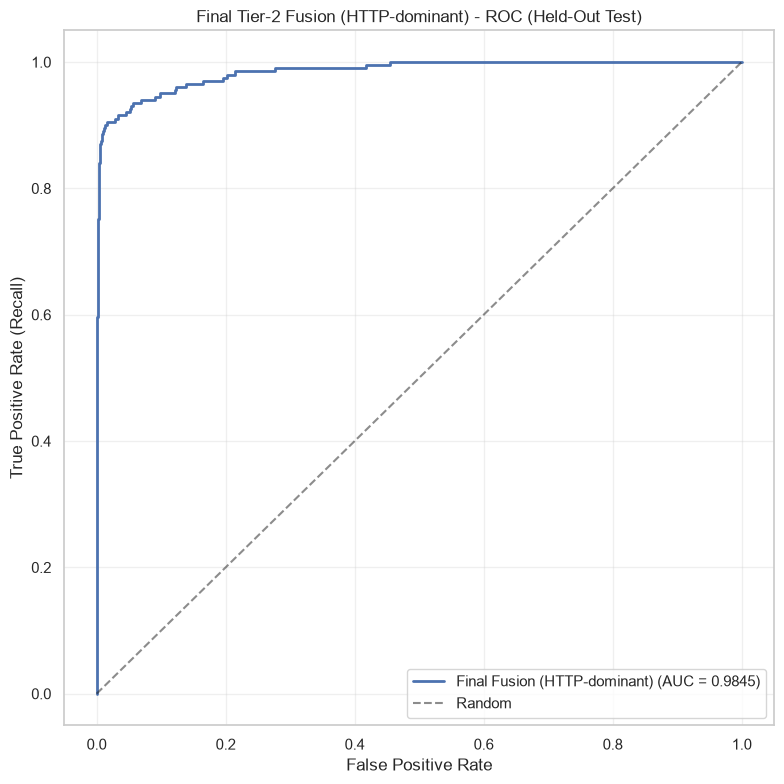

In [6]:
fpr_arr, tpr_arr, _ = roc_curve(y_true, s_test)
plt.figure(figsize=(8, 8))
plt.plot(fpr_arr, tpr_arr, 'b-', linewidth=2,
         label=f'Final Fusion ({FROZEN_STRATEGY}) (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title(f'Final Tier-2 Fusion ({FROZEN_STRATEGY}) - ROC (Held-Out Test)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Validation plots (selection evidence)

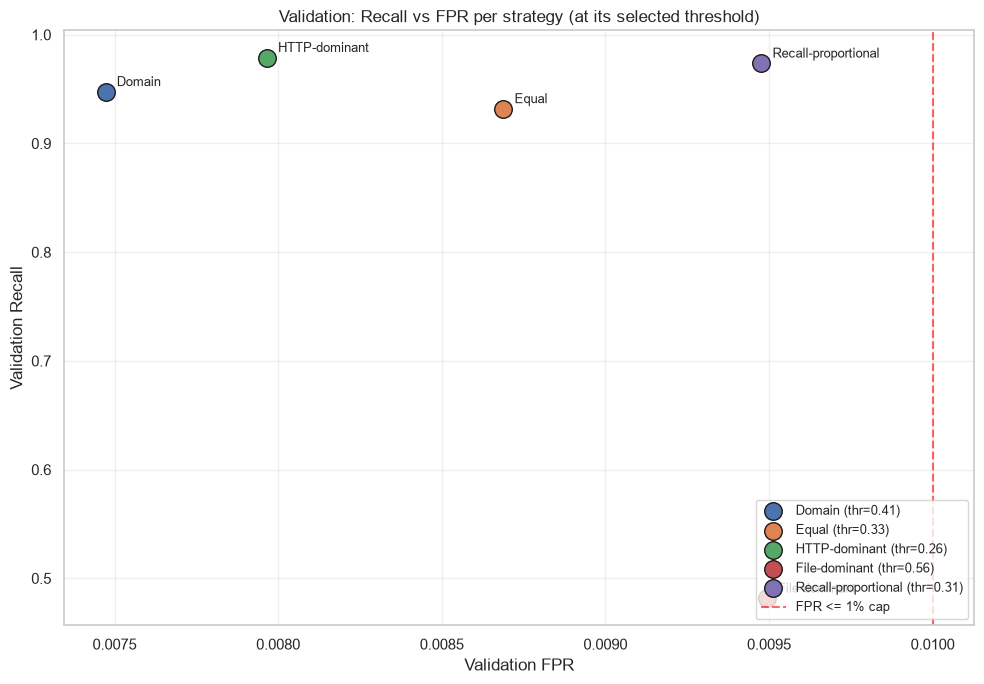

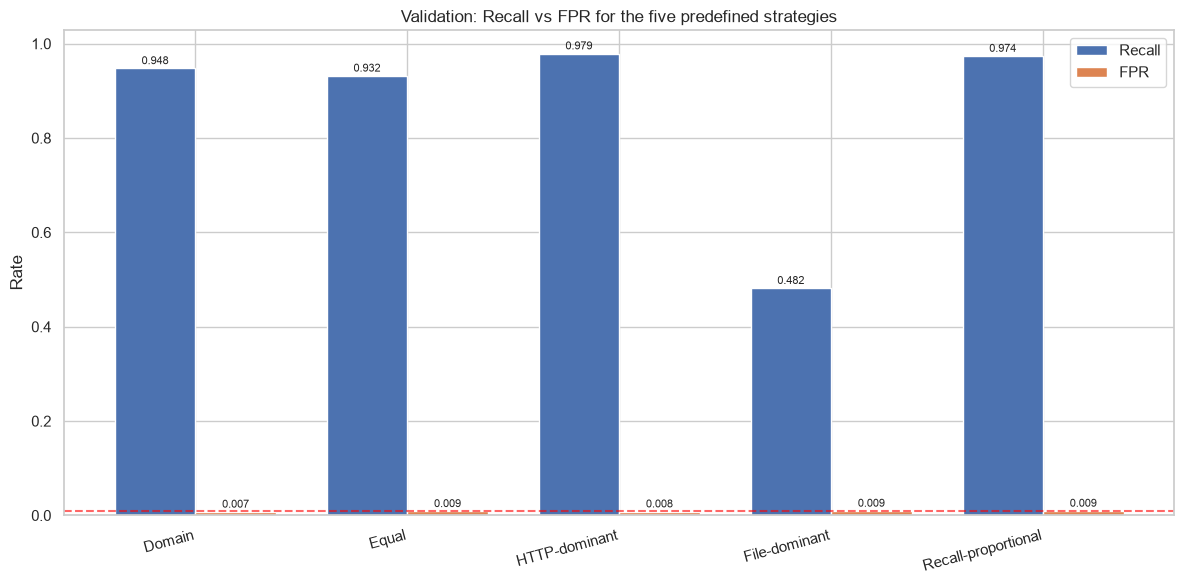

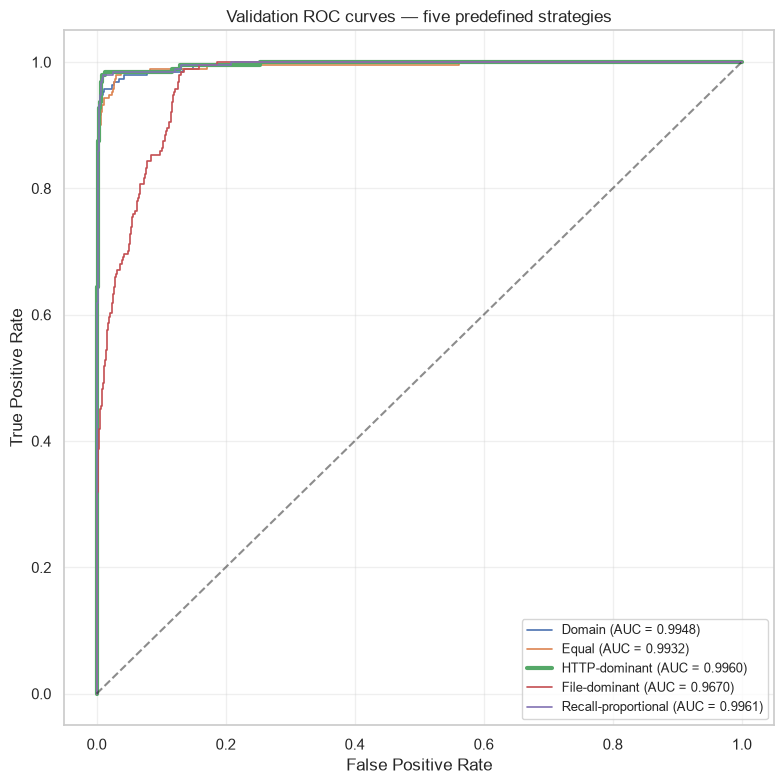

In [7]:
# A. Validation Recall vs FPR at each strategy's selected threshold
fig, ax = plt.subplots(figsize=(10, 7))
for _, r in comp.iterrows():
    ax.scatter(r['Validation FPR'], r['Validation Recall'], s=160,
               label=f"{r['Strategy']} (thr={r['Best Threshold']:.2f})", edgecolors='k')
    ax.annotate(r['Strategy'], (r['Validation FPR'], r['Validation Recall']),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.axvline(FPR_CAP, color='red', linestyle='--', alpha=0.6, label='FPR <= 1% cap')
ax.set_xlabel('Validation FPR')
ax.set_ylabel('Validation Recall')
ax.set_title('Validation: Recall vs FPR per strategy (at its selected threshold)')
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# B. Validation Recall & FPR bar comparison
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(comp))
w = 0.38
ax.bar(x - w/2, comp['Validation Recall'], w, label='Recall', color='#4C72B0')
ax.bar(x + w/2, comp['Validation FPR'], w, label='FPR', color='#DD8452')
ax.set_xticks(x)
ax.set_xticklabels(comp['Strategy'], rotation=15, ha='right')
ax.set_ylabel('Rate')
ax.set_title('Validation: Recall vs FPR for the five predefined strategies')
ax.legend()
ax.axhline(FPR_CAP, color='red', linestyle='--', alpha=0.6)
for xi, (rv, fv) in enumerate(zip(comp['Validation Recall'], comp['Validation FPR'])):
    ax.annotate(f'{rv:.3f}', (xi - w/2, rv), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8)
    ax.annotate(f'{fv:.3f}', (xi + w/2, fv), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8)
plt.tight_layout()
plt.show()

# C. Validation ROC curves for the five strategies
plt.figure(figsize=(8, 8))
for name, w in strategies.items():
    s = fused(df_val, w)
    fpr_a, tpr_a, _ = roc_curve(df_val['label'], s)
    a = roc_auc_score(df_val['label'], s)
    lw = 3 if name == FROZEN_STRATEGY else 1.2
    plt.plot(fpr_a, tpr_a, linewidth=lw, label=f'{name} (AUC = {a:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Validation ROC curves — five predefined strategies')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Comparison vs Week-1 Random Forest Binary (exact established protocol)

In [8]:
# Exact Week-1 RF Binary protocol (week1_random_forest_binary.ipynb):
# same features_clean.parquet, same canonical 60/20/20 split, RF(200, balanced, 42),
# Youden's-J threshold on validation, evaluate once on test.
from sklearn.ensemble import RandomForestClassifier

print('Replicating the existing Week-1 Binary RF baseline...')
X_w1 = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'features_clean.parquet')
tr_u = np.load(PROJECT_ROOT / 'data' / 'user_splits' / 'train_users.npy')
va_u = np.load(PROJECT_ROOT / 'data' / 'user_splits' / 'val_users.npy')
te_u = np.load(PROJECT_ROOT / 'data' / 'user_splits' / 'test_users.npy')

tr_df = X_w1[X_w1['user'].isin(tr_u)]
va_df = X_w1[X_w1['user'].isin(va_u)]
te_df = X_w1[X_w1['user'].isin(te_u)]
feat = [c for c in X_w1.columns if c not in ('user', 'insider')]

Xtr, ytr = tr_df[feat], tr_df['insider'].astype(int).values
Xva, yva = va_df[feat], va_df['insider'].astype(int).values
Xte, yte = te_df[feat], te_df['insider'].astype(int).values

model_w1 = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
model_w1.fit(Xtr, ytr)
p_va = model_w1.predict_proba(Xva)[:, 1]
best_j, best_t = -1.0, 0.5
for t in np.arange(0.05, 0.96, 0.05):
    preds = (p_va > t).astype(int)
    tn0, fp0, fn0, tp0 = confusion_matrix(yva, preds).ravel()
    fpr0 = fp0 / (fp0 + tn0) if (fp0 + tn0) > 0 else 0.0
    rec0 = recall_score(yva, preds, zero_division=0)
    j = rec0 - fpr0
    if j > best_j:
        best_j, best_t = j, t
w1_thr = float(best_t)
p_te = model_w1.predict_proba(Xte)[:, 1]
y_pred_w1 = (p_te > w1_thr).astype(int)
w1 = {
    'Recall': recall_score(yte, y_pred_w1, zero_division=0),
    'FPR': 0.0,
    'Precision': precision_score(yte, y_pred_w1, zero_division=0),
    'F1': f1_score(yte, y_pred_w1, zero_division=0),
    'Accuracy': accuracy_score(yte, y_pred_w1),
    'ROC-AUC': roc_auc_score(yte, p_te),
}
tn_w1, fp_w1, fn_w1, tp_w1 = confusion_matrix(yte, y_pred_w1).ravel()
w1['FPR'] = fp_w1 / (fp_w1 + tn_w1) if (fp_w1 + tn_w1) > 0 else 0
print(f'Week-1 RF: thr={w1_thr:.2f} | Recall={w1["Recall"]:.4f} FPR={w1["FPR"]:.4f} '
      f'Precision={w1["Precision"]:.4f} F1={w1["F1"]:.4f} Accuracy={w1["Accuracy"]:.4f} ROC-AUC={w1["ROC-AUC"]:.4f}')

# Existing Domain Fusion reference (40/40/10/10) at its own validation-tuned threshold
dom = strategies['Domain']
s_dom_val = fused(df_val, dom)
s_dom_test = fused(df_test, dom)
best_dom = None
for t in thresholds:
    preds = (s_dom_val > t).astype(int)
    rec = recall_score(df_val['label'], preds, zero_division=0)
    tn0, fp0, fn0, tp0 = confusion_matrix(df_val['label'], preds).ravel()
    fpr0 = fp0 / (fp0 + tn0) if (fp0 + tn0) > 0 else 0
    if best_dom is None or (fpr0 <= FPR_CAP and rec > best_dom[1]) or (fpr0 <= FPR_CAP and best_dom[0] > FPR_CAP):
        best_dom = (fpr0, rec, t)
dom_thr = best_dom[2]
preds_dom = (s_dom_test > dom_thr).astype(int)
dom_res = {
    'Recall': recall_score(df_test['label'], preds_dom, zero_division=0),
    'FPR': 0.0,
    'ROC-AUC': roc_auc_score(df_test['label'], s_dom_test),
}
tn_d, fp_d, fn_d, tp_d = confusion_matrix(df_test['label'], preds_dom).ravel()
dom_res['FPR'] = fp_d / (fp_d + tn_d) if (fp_d + tn_d) > 0 else 0
print(f'Existing Domain Fusion: thr={dom_thr:.2f} | Recall={dom_res["Recall"]:.4f} FPR={dom_res["FPR"]:.4f} AUC={dom_res["ROC-AUC"]:.4f}')

comparison_table = f"""
| Metric | Week-1 RF Binary | Existing Domain Fusion | Final Selected Fusion |
| :--- | :--- | :--- | :--- |
| **Recall** | {w1['Recall']:.4f} | {dom_res['Recall']:.4f} | {test_recall:.4f} |
| **FPR** | {w1['FPR']:.4f} | {dom_res['FPR']:.4f} | {test_fpr:.4f} |
| **Precision** | {w1['Precision']:.4f} | — | {test_prec:.4f} |
| **F1** | {w1['F1']:.4f} | — | {test_f1:.4f} |
| **Accuracy** | {w1['Accuracy']:.4f} | — | {test_acc:.4f} |
| **ROC-AUC** | {w1['ROC-AUC']:.4f} | {dom_res['ROC-AUC']:.4f} | {test_auc:.4f} |
"""
display(Markdown('### Final comparison'))
display(Markdown(comparison_table))

# Compact 3-way table (Recall / FPR / AUC)
three = pd.DataFrame({
    'Configuration': ['Week-1 RF Binary', 'Existing Domain Fusion', f'Final Selected Fusion ({FROZEN_STRATEGY})'],
    'Recall': [w1['Recall'], dom_res['Recall'], test_recall],
    'FPR': [w1['FPR'], dom_res['FPR'], test_fpr],
    'AUC': [w1['ROC-AUC'], dom_res['ROC-AUC'], test_auc],
})
display(Markdown('### Three-way comparison (Recall / FPR / AUC)'))
display(three.round(4))

Replicating the existing Week-1 Binary RF baseline...
Week-1 RF: thr=0.05 | Recall=0.6418 FPR=0.0089 Precision=0.1812 F1=0.2826 Accuracy=0.9900 ROC-AUC=0.9410
Existing Domain Fusion: thr=0.40 | Recall=0.8756 FPR=0.0125 AUC=0.9842


### Final comparison


| Metric | Week-1 RF Binary | Existing Domain Fusion | Final Selected Fusion |
| :--- | :--- | :--- | :--- |
| **Recall** | 0.6418 | 0.8756 | 0.8856 |
| **FPR** | 0.0089 | 0.0125 | 0.0097 |
| **Precision** | 0.1812 | — | 0.2312 |
| **F1** | 0.2826 | — | 0.3666 |
| **Accuracy** | 0.9900 | — | 0.9900 |
| **ROC-AUC** | 0.9410 | 0.9842 | 0.9845 |


### Three-way comparison (Recall / FPR / AUC)

,Configuration,Recall,FPR,AUC
0,Week-1 RF Binary,0.6418,0.0089,0.9410
1,Existing Domain Fusion,0.8756,0.0125,0.9842
2,Final Selected Fusion (HTTP-dominant),0.8856,0.0097,0.9845


## 9. Summary of frozen configuration

In [9]:
print('=' * 55)
print('  FINAL TIER-2 FUSION CONFIGURATION (to freeze for LangGraph/Tier-3)')
print('=' * 55)
print(f'  Weight strategy   : {FROZEN_STRATEGY}')
print(f'  HTTP weight       : {FROZEN_WEIGHTS["http"]:.4f}')
print(f'  File/Device weight: {FROZEN_WEIGHTS["file_device"]:.4f}')
print(f'  Logon weight      : {FROZEN_WEIGHTS["logon"]:.4f}')
print(f'  Email weight      : {FROZEN_WEIGHTS["email"]:.4f}')
print(f'  Decision threshold: {FROZEN_THRESHOLD:.4f}')
print(f'  Validation Recall : {float(selected["Validation Recall"]):.4f}')
print(f'  Validation FPR    : {float(selected["Validation FPR"]):.4f}')
print(f'  Validation AUC    : {float(selected["Validation AUC"]):.4f}')
print(f'  Test Recall       : {test_recall:.4f}')
print(f'  Test FPR          : {test_fpr:.4f}')
print(f'  Test ROC-AUC      : {test_auc:.4f}')
print('=' * 55)

  FINAL TIER-2 FUSION CONFIGURATION (to freeze for LangGraph/Tier-3)
  Weight strategy   : HTTP-dominant
  HTTP weight       : 0.6000
  File/Device weight: 0.2000
  Logon weight      : 0.1000
  Email weight      : 0.1000
  Decision threshold: 0.2600
  Validation Recall : 0.9791
  Validation FPR    : 0.0080
  Validation AUC    : 0.9960
  Test Recall       : 0.8856
  Test FPR          : 0.0097
  Test ROC-AUC      : 0.9845
